# Practical 5 · Customer segments with k-means (unsupervised learning)

**Goal:** without using the churn answer, find natural **groups** of customers, describe them, and turn them into marketing actions.

This is **unsupervised** learning: there is no target. Some recipe steps change:
- no target, so no train/test split for accuracy (we still keep the habit of fitting on training data)
- **scaling is essential** (k-means measures distances)
- "evaluation" means: are the groups well separated, stable, and **useful**?

## Step 0–1 · Tools and data

In [1]:
import os
from urllib.request import urlretrieve
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings; warnings.filterwarnings('ignore')
sns.set_style('whitegrid'); plt.rcParams['figure.figsize'] = (8, 4.5)

url = 'https://raw.githubusercontent.com/MusaBangash/Python-Variables/main/ml/data/telco-churn.csv'
if not os.path.exists('telco-churn.csv'):
    urlretrieve(url, 'telco-churn.csv')
df = pd.read_csv('telco-churn.csv')
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce').fillna(0)
print(df.shape)

(7043, 21)


## Step 11 · Choose and build the features for grouping
We describe each customer's **behaviour** with three numbers:
- `tenure`: months with the company
- `MonthlyCharges`: monthly bill
- `n_services`: how many services they use (phone, internet, security, streaming…)

We deliberately do **not** use `Churn`. We'll check afterwards whether the groups say something about churn.

In [2]:
services = ['PhoneService', 'MultipleLines', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies']
df['n_services'] = (df[services] == 'Yes').sum(axis=1) + (df['InternetService'] != 'No').astype(int)
features = ['tenure', 'MonthlyCharges', 'n_services']
df[features].describe().round(1)

,tenure,MonthlyCharges,n_services
count,7043.0,7043.0,7043.0
mean,32.4,64.8,4.1
std,24.6,30.1,2.3
min,0.0,18.2,1.0
25%,9.0,35.5,2.0
50%,29.0,70.4,4.0
75%,55.0,89.8,6.0
max,72.0,118.8,9.0


## Step 10 · Why scaling is essential here
k-means groups customers by **distance**. Without scaling, a column measured in big numbers dominates the distance. Let's measure how much of the total spread each column has, raw vs scaled:

In [3]:
from sklearn.preprocessing import StandardScaler
raw_var = df[['tenure', 'MonthlyCharges', 'TotalCharges']].var()
print('Share of total variance (raw units):')
print((raw_var / raw_var.sum()).round(4))

Share of total variance (raw units):
tenure            0.0001
MonthlyCharges    0.0002
TotalCharges      0.9997
dtype: float64


In raw units, **TotalCharges** (thousands of dollars) holds about **99.97%** of all the spread: k-means would just slice customers by total bill. That's why we don't use TotalCharges here, and why we **always scale**: after StandardScaler every feature has spread 1 and gets a fair vote.

In [4]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df[features])
print('Means after scaling:', X_scaled.mean(axis=0).round(2), '| spreads:', X_scaled.std(axis=0).round(2))

Means after scaling: [-0. -0. -0.] | spreads: [1. 1. 1.]


## Step 15 · k-means: how many groups (k)? Two tests
- **Elbow (inertia):** total squared distance from each customer to its group centre. It always falls as k grows; look for the bend.
- **Silhouette:** for each customer, how much closer it is to its own group than to the nearest other group (−1 to 1, higher = better separated).

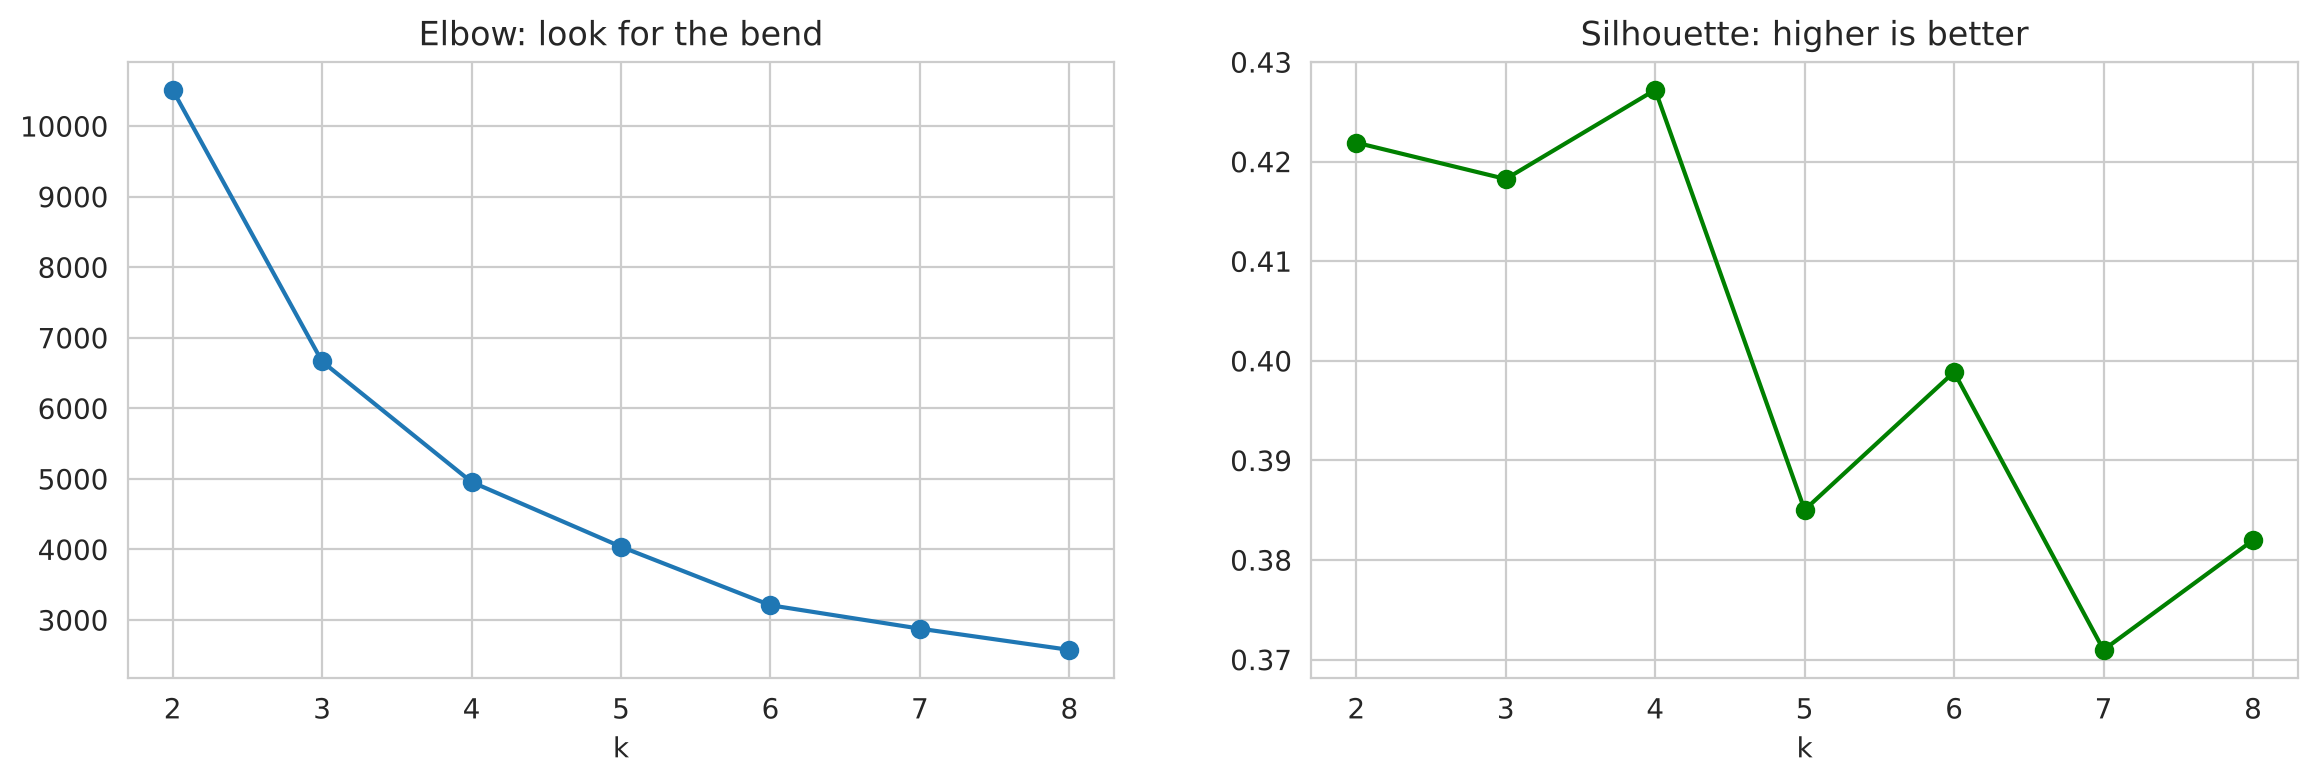

,k,inertia,silhouette
0,2,10512.588,0.422
1,3,6663.199,0.418
2,4,4955.524,0.427
3,5,4037.567,0.385
4,6,3208.168,0.399
5,7,2876.278,0.371
6,8,2575.397,0.382


In [5]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
rows = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, n_init=10, random_state=0).fit(X_scaled)
    rows.append({'k': k, 'inertia': km.inertia_, 'silhouette': silhouette_score(X_scaled, km.labels_, sample_size=4000, random_state=0)})
choose = pd.DataFrame(rows)
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].plot(choose['k'], choose['inertia'], 'o-'); ax[0].set_title('Elbow: look for the bend'); ax[0].set_xlabel('k')
ax[1].plot(choose['k'], choose['silhouette'], 'o-', color='green'); ax[1].set_title('Silhouette: higher is better'); ax[1].set_xlabel('k')
plt.show()
choose.round(3)

The elbow bends around **k = 4**, and silhouette is highest at **k = 4** (with k = 2 close behind). We choose **4** because it gives the business more useful, nameable groups. There is no single "true" k: shortlist with the tests, then choose what people can **act on**.

## Step 15 · Fit k-means with k = 4

In [6]:
kmeans = KMeans(n_clusters=4, n_init=10, random_state=0).fit(X_scaled)
df['segment'] = kmeans.labels_
centres = pd.DataFrame(scaler.inverse_transform(kmeans.cluster_centers_), columns=features).round(1)
centres['customers'] = df['segment'].value_counts().sort_index().values
centres

,tenure,MonthlyCharges,n_services,customers
0,10.2,29.1,1.6,1503
1,57.4,91.3,6.7,2156
2,14.9,77.2,4.2,2412
3,54.5,30.1,2.1,972


The **centres** (converted back to real units) describe the typical customer of each segment.

## Step 16 · Describe and name the segments, then check churn (never used for grouping)

In [7]:
profile = df.groupby('segment').agg(customers=('segment', 'size'), tenure=('tenure', 'mean'),
                                    monthly_bill=('MonthlyCharges', 'mean'), services=('n_services', 'mean'),
                                    month_to_month=('Contract', lambda s: (s == 'Month-to-month').mean()),
                                    churn_rate=('Churn', lambda s: (s == 'Yes').mean())).round(2)
def name(row):
    age = 'New' if row.tenure < 30 else 'Loyal'
    bill = 'high bill' if row.monthly_bill > 60 else 'budget'
    return f'{age}, {bill}'
profile['name'] = profile.apply(name, axis=1)
profile.sort_values('churn_rate', ascending=False)

,customers,tenure,monthly_bill,services,month_to_month,churn_rate,name
segment,,,,,,,
2,2412,14.90,77.20,4.24,0.86,0.47,"New, high bill"
0,1503,10.23,29.13,1.65,0.72,0.24,"New, budget"
1,2156,57.39,91.30,6.72,0.26,0.16,"Loyal, high bill"
3,972,54.47,30.13,2.06,0.16,0.04,"Loyal, budget"


**k-means never saw the churn column**, yet churn ranges from about **4%** (loyal, budget customers) to about **47%** (new, high-bill customers). Structure found without answers turned out to matter.

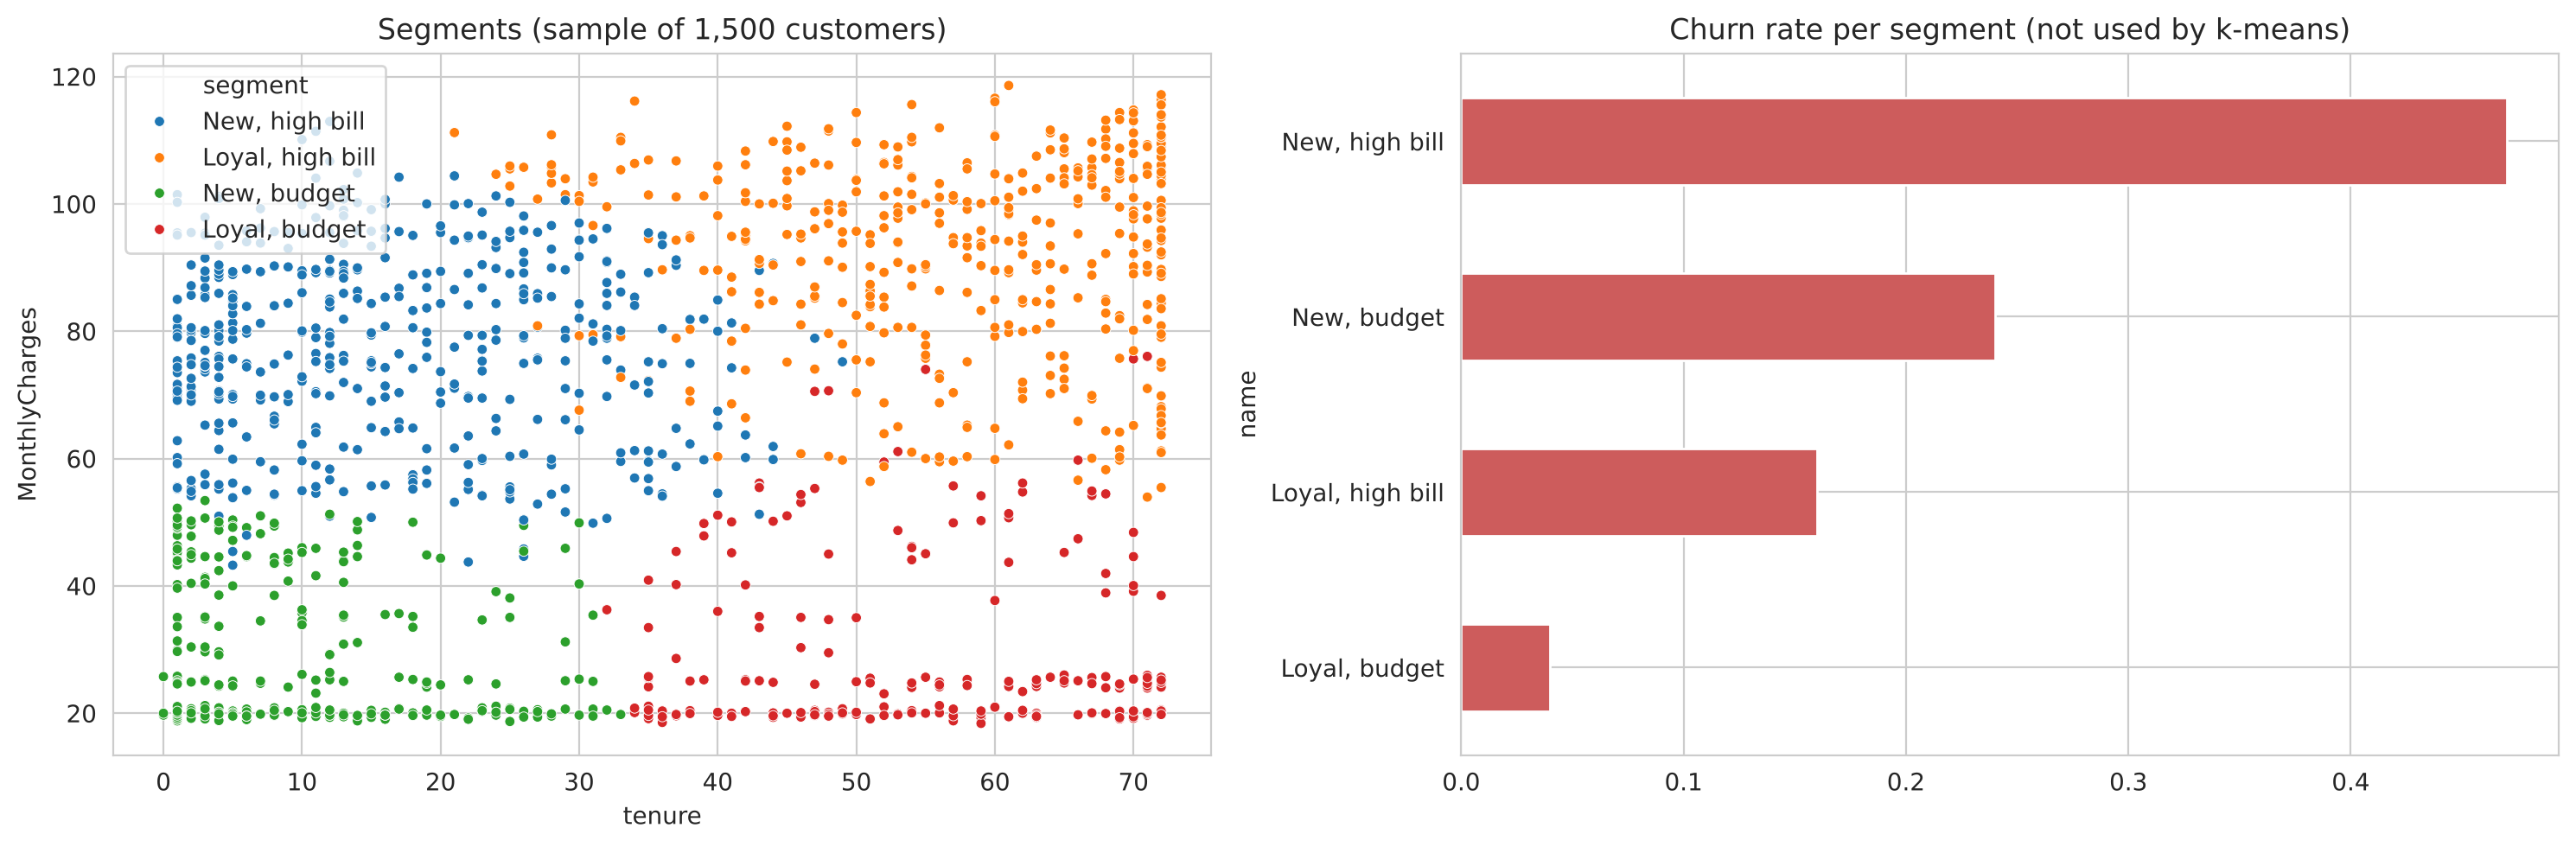

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
names = profile['name'].to_dict()
sample = df.sample(1500, random_state=0)
sns.scatterplot(data=sample, x='tenure', y='MonthlyCharges', hue=sample['segment'].map(names), s=18, ax=ax[0])
ax[0].set_title('Segments (sample of 1,500 customers)')
profile.set_index('name')['churn_rate'].sort_values().plot.barh(ax=ax[1], color='indianred')
ax[1].set_title('Churn rate per segment (not used by k-means)'); plt.tight_layout(); plt.show()

### From segments to actions

In [9]:
actions = {'New, high bill': 'discount for switching to a 1-year contract; early check-in call',
           'New, budget': 'onboarding help; free add-on trial',
           'Loyal, high bill': 'loyalty reward; check service quality',
           'Loyal, budget': 'thank-you message; gentle upsell'}
profile.assign(action=profile['name'].map(actions))[['name', 'customers', 'churn_rate', 'action']].sort_values('churn_rate', ascending=False)

,name,customers,churn_rate,action
segment,,,,
2,"New, high bill",2412,0.47,discount for switching to a 1-year contract; e...
0,"New, budget",1503,0.24,onboarding help; free add-on trial
1,"Loyal, high bill",2156,0.16,loyalty reward; check service quality
3,"Loyal, budget",972,0.04,thank-you message; gentle upsell


## Step 17 · Is the grouping stable? Random starts
k-means starts from random centres and can land in a worse solution. `n_init=10` runs 10 starts and keeps the best. Let's compare runs with one start vs ten, using the **adjusted Rand index** (ARI: 1 = identical groupings, 0 = random).

In [10]:
from sklearn.metrics import adjusted_rand_score
one = [KMeans(4, n_init=1, random_state=s).fit_predict(X_scaled) for s in range(10)]
ten = [KMeans(4, n_init=10, random_state=s).fit_predict(X_scaled) for s in range(10)]
print('n_init=1  : worst agreement between runs', round(min(adjusted_rand_score(one[0], o) for o in one[1:]), 3))
print('n_init=10 : worst agreement between runs', round(min(adjusted_rand_score(ten[0], t) for t in ten[1:]), 3))

n_init=1  : worst agreement between runs 0.507
n_init=10 : worst agreement between runs 0.996


With a single start, some runs give quite different groups. With 10 starts the result is practically identical every time. **Always use n_init ≥ 10 and a fixed random_state.**

## k-means' blind spot: it only finds round blobs
k-means draws straight-edged regions around centres. Two curved, interlocking groups defeat it. **DBSCAN** grows groups through dense neighbourhoods, follows any shape, and marks lonely points as noise.

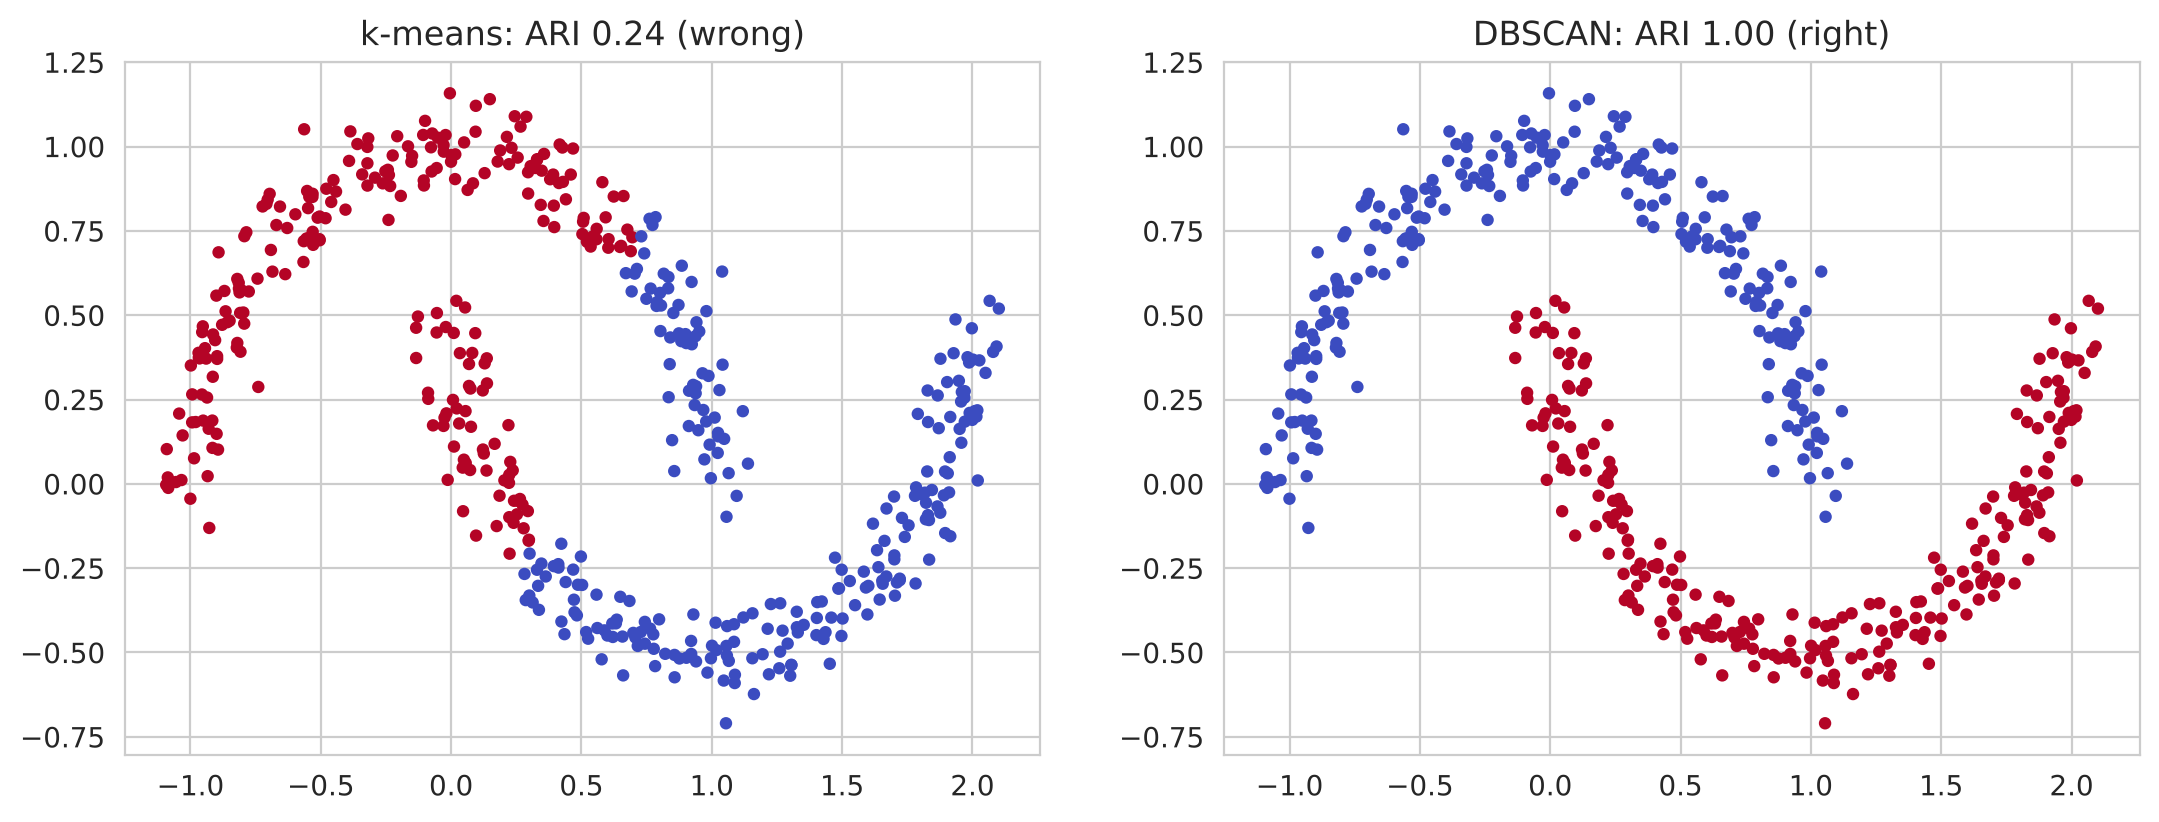

In [11]:
from sklearn.datasets import make_moons
from sklearn.cluster import DBSCAN
Xm, ym = make_moons(500, noise=0.07, random_state=0)
km_labels = KMeans(2, n_init=10, random_state=0).fit_predict(Xm)
db_labels = DBSCAN(eps=0.2, min_samples=5).fit_predict(Xm)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].scatter(Xm[:, 0], Xm[:, 1], c=km_labels, cmap='coolwarm', s=12); ax[0].set_title(f'k-means: ARI {adjusted_rand_score(ym, km_labels):.2f} (wrong)')
ax[1].scatter(Xm[:, 0], Xm[:, 1], c=db_labels, cmap='coolwarm', s=12); ax[1].set_title(f'DBSCAN: ARI {adjusted_rand_score(ym, db_labels):.2f} (right)')
plt.show()

## Step 20 · Save the segmentation as one pipeline
New customers must be scaled with the **same** scaler before k-means assigns them a segment, so we save both together.

In [12]:
from sklearn.pipeline import Pipeline
import joblib
segmenter = Pipeline([('scale', StandardScaler()), ('kmeans', KMeans(4, n_init=10, random_state=0))]).fit(df[features])
joblib.dump({'pipeline': segmenter, 'names': names}, 'segmenter.joblib')

saved = joblib.load('segmenter.joblib')
new = pd.DataFrame([{'tenure': 2, 'MonthlyCharges': 95.0, 'n_services': 6}, {'tenure': 60, 'MonthlyCharges': 25.0, 'n_services': 1}])
new['segment'] = [saved['names'][s] for s in saved['pipeline'].predict(new[features])]
new

,tenure,MonthlyCharges,n_services,segment
0,2,95.0,6,"New, high bill"
1,60,25.0,1,"Loyal, budget"


*(The saved pipeline is refitted on all customers, so segment numbers can differ from the exploration above; we map them to names through the same `names` table only because `random_state` and data are identical.)*

## Summary
| Step | Lesson |
|---|---|
| no target | unsupervised: we find structure, not answers |
| scaling | essential for any distance-based method |
| choosing k | elbow + silhouette to shortlist, business sense to decide |
| profiling | name segments by their centres; churn 4%–47% without ever seeing churn |
| stability | n_init ≥ 10, fixed random_state |
| limits | k-means needs round blobs; DBSCAN for odd shapes |

## Exercises
1. Run k-means with k = 3 and k = 5. Are the segments easier or harder to name and act on?
2. Add `TotalCharges` to the features (scaled). Do the segments change? Why might that be redundant with tenure × MonthlyCharges?
3. Add the segment as a feature to the logistic regression from Practical 2. Does ROC AUC improve? Why or why not?